### Zadania

Główna część listy (zadania 1-3) dotyczy detekcji krawędzi na obrazach. Zadanie 4 kontynuuje temat binaryzacji, skupiając się na operacjach globalnych (przekształceniach histogramu).

In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [2]:
from scipy import ndimage as ndi
from skimage.feature import peak_local_max
from skimage.segmentation import watershed

plt.rcParams['figure.dpi'] = 72  # mniejsze PNG w notebooku

def ell(k):
    return cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k))

def iou(a, b):
    a, b = a > 0, b > 0
    return (a & b).sum() / (a | b).sum()

def norm99(g):
    """Skalowanie do [0, 1] względem 99. percentyla (żeby pojedyncze maksima nie „gasiły” mapy)."""
    return np.clip(g / np.percentile(g, 99), 0, 1)

def grad_mag(img, ksize=3, sigma=0):
    """Moduł gradientu Sobela, opcjonalnie po rozmyciu Gaussa o odchyleniu `sigma`."""
    if sigma > 0:
        img = cv2.GaussianBlur(img, (0, 0), sigma)
    return np.hypot(cv2.Sobel(img, cv2.CV_64F, 1, 0, ksize=ksize), cv2.Sobel(img, cv2.CV_64F, 0, 1, ksize=ksize))

def show_grid(images, titles, ncols=None, size=4, cmap='gray', **kw):
    """Siatka obrazów z tytułami."""
    ncols = ncols or len(images)
    nrows = -(-len(images) // ncols)
    h, w = images[0].shape[:2]
    _, axes = plt.subplots(nrows, ncols, figsize=(size * ncols, size * nrows * h / w + 0.7 * nrows), squeeze=False, constrained_layout=True)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, img, title in zip(axes.ravel(), images, titles):
        ax.imshow(img, cmap=cmap, **kw); ax.set_title(title)
    plt.show()

##### Zad. 1: Wyznaczenie gradientów

Wykonaj dla obrazu `coins` sztuczny obraz ilustrujący wielkość (moduł) wektora gradientu w danym punkcie. Do wyświetlenia użyj [mapy kolorów](https://matplotlib.org/stable/tutorials/colors/colormaps.html) `hot` do oznaczenia wielkości gradientu odpowiednim kolorem – im większa wartość, tym jaśniej (_mapa ciepła_).  
Gdzie gradienty są bliskie zera?  
Czy uzyskany wynik pozwoliłby np. na detekcję poszczególnych obiektów?

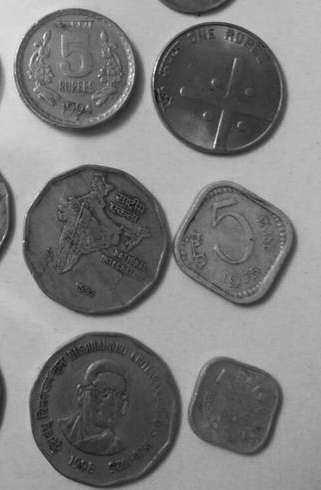

In [3]:
coins = cv2.imread('Monety_szare.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins)

Rozwiązanie:

**Wzorzec konturów monet** (do metryk w zad. 1–3) wyznaczam z *czystego* obrazu: Otsu → morfologia → watershed (rozdziela stykające się monety) → otoczka wypukła każdej monety. Wychodzi 6 pełnych monet i 3 ucięte brzegiem obrazu.
- **kontrast konturów** = średni |∇f| na konturach monet / średni |∇f| poza nimi,
- **F1 krawędzi** = zgodność krawędzi z konturami wzorca (tolerancja 2 px),
- **IoU obiektów** = obszary zamknięte przez krawędzie vs maska wzorca.

In [4]:
_, m = cv2.threshold(cv2.medianBlur(coins, 5), 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
m = ndi.binary_fill_holes(cv2.morphologyEx(cv2.morphologyEx(m, cv2.MORPH_OPEN, ell(5)), cv2.MORPH_CLOSE, ell(9)))
dist = ndi.distance_transform_edt(m)
peaks = peak_local_max(dist, min_distance=30, threshold_abs=3, exclude_border=False, labels=ndi.label(m)[0])
markers = np.zeros(m.shape, int); markers[tuple(peaks.T)] = np.arange(1, len(peaks) + 1)
coin_labels = watershed(-dist, markers, mask=m)

gt_mask, gt_edges = np.zeros_like(coins), np.zeros_like(coins)
for i in range(1, coin_labels.max() + 1):
    contours = cv2.findContours((coin_labels == i).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]
    hull = cv2.fillPoly(np.zeros_like(coins), [cv2.convexHull(np.vstack(contours))], 255)
    gt_mask |= hull
    gt_edges |= hull - cv2.erode(hull, np.ones((3, 3), np.uint8))
N_FULL = 6  # pełne monety (pozostałe 3 są ucięte przez brzeg obrazu)

TOL = 2  # tolerancja położenia krawędzi [px]
gt_near = cv2.dilate(gt_edges, ell(2 * TOL + 1)) > 0
near_edge = cv2.dilate(gt_edges, ell(7)) > 0

def edge_contrast(g):
    return g[near_edge].mean() / g[~near_edge].mean()

def edge_f1(edges):
    e = edges > 0
    precision = (e & gt_near).sum() / max(e.sum(), 1)
    recall = ((gt_edges > 0) & (cv2.dilate(edges, ell(2 * TOL + 1)) > 0)).sum() / (gt_edges > 0).sum()
    return 2 * precision * recall / max(precision + recall, 1e-9)

def edges_to_regions(edges, close=5, min_area=3000):
    """Obiekty = obszary zamknięte krawędzią (składowe tła niestykające się z brzegiem obrazu); lista masek."""
    if close > 1:
        edges = cv2.morphologyEx(edges, cv2.MORPH_CLOSE, ell(close))
    n, labels, stats, _ = cv2.connectedComponentsWithStats(255 - edges, connectivity=4)
    border = set(np.r_[labels[0], labels[-1], labels[:, 0], labels[:, -1]])
    keep = [i for i in range(1, n) if i not in border and stats[i, cv2.CC_STAT_AREA] >= min_area]
    regions = [(ndi.binary_fill_holes(labels == i) * 255).astype(np.uint8) for i in keep]
    return [cv2.dilate(r, ell(close)) for r in regions] if close > 1 else regions  # dylatacja oddaje grubość domkniętej krawędzi

def edges_to_objects(edges, close=5, min_area=3000):
    """(maska wszystkich obiektów, liczba obiektów)."""
    regions = edges_to_regions(edges, close, min_area)
    return (np.max(regions, axis=0) if regions else np.zeros_like(edges)), len(regions)

**1.1 Moduł gradientu (Sobel 3×3), mapa ciepła.**

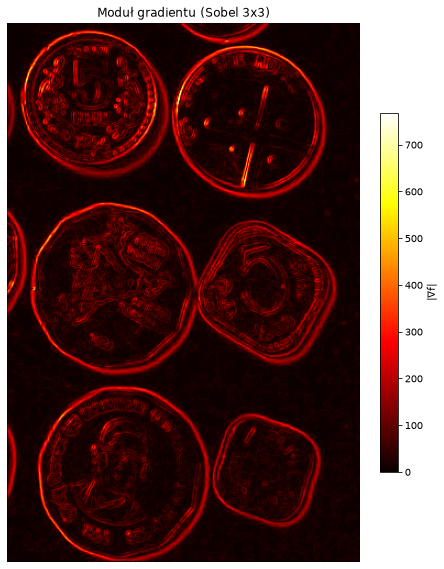

In [5]:
plt.figure(figsize=(7, 10))
plt.imshow(grad_mag(coins), cmap='hot'); plt.colorbar(label='|∇f|', fraction=0.046)
plt.title('Moduł gradientu (Sobel 3x3)'); plt.axis('off'); plt.show()

**1.2 Wpływ wygładzania przed gradientem:** od braku rozmycia, przez umiarkowane, do bardzo silnego (Gauss σ ∈ {0, 2, 6, 15}).

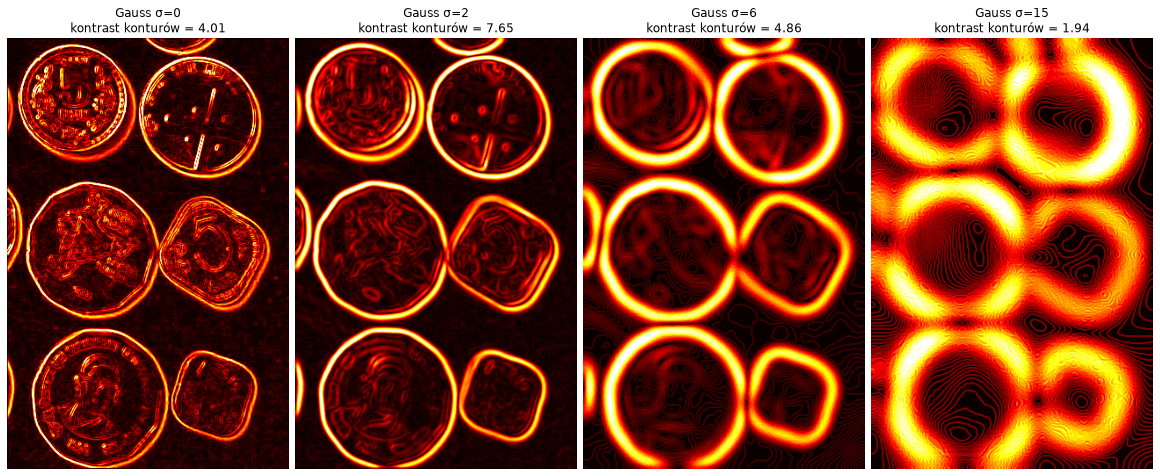

In [6]:
sigmas = [0, 2, 6, 15]
grads = [grad_mag(coins, sigma=s) for s in sigmas]
show_grid([norm99(g) for g in grads], [f'Gauss σ={s}\nkontrast konturów = {edge_contrast(g):.2f}' for s, g in zip(sigmas, grads)], cmap='hot')

**1.3 Czy sam gradient pozwala wykryć obiekty?** Próg |∇f| od bardzo niskiego (połowa pikseli to „krawędź”) do bardzo wysokiego (1% pikseli), potem obszary zamknięte przez „krawędzie” → obiekty.

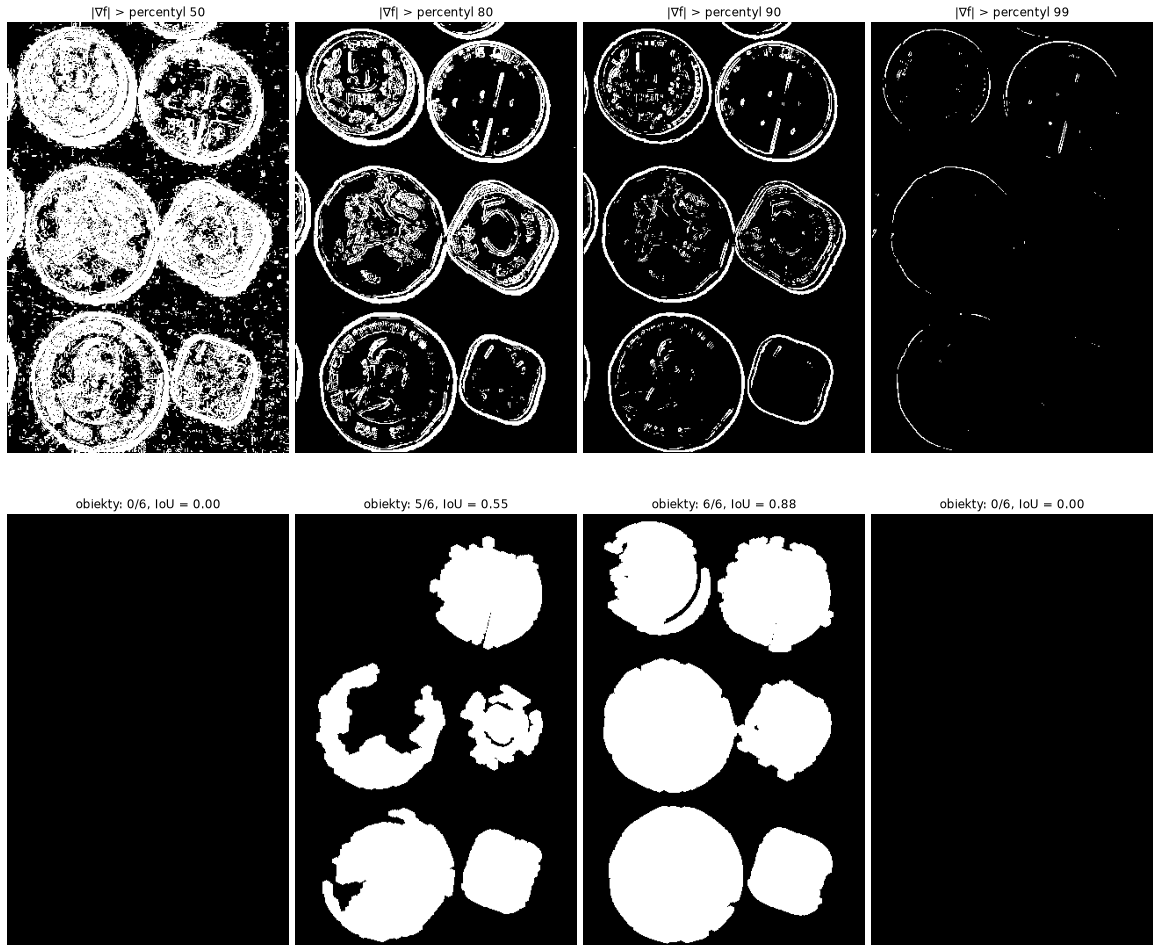

In [7]:
g = grad_mag(coins)
percentiles = [50, 80, 90, 99]
masks = [((g > np.percentile(g, p)) * 255).astype(np.uint8) for p in percentiles]
objects = [edges_to_objects(m) for m in masks]
show_grid(masks + [o for o, _ in objects],
          [f'|∇f| > percentyl {p}' for p in percentiles] + [f'obiekty: {n}/{N_FULL}, IoU = {iou(o, gt_mask):.2f}' for o, n in objects], ncols=4)

**Wnioski (zad. 1)**
- **Gdzie gradient ≈ 0?** Na jednolitym tle i w płaskich polach monet. Duże wartości dają zewnętrzne kontury, ale też relief monet (cyfry, napisy, rant) i cień.
- Wygładzanie przed gradientem tłumi drobny relief szybciej niż kontury: kontrast konturów rośnie z 4.0 (σ=0) do 7.7 (σ=2). Przy skrajnym σ=15 kontury zamieniają się w szerokie plamy i stykające się monety zlewają (kontrast 1.9, gorzej niż bez rozmycia).
- **Czy to wystarczy do detekcji?** Sam gradient to mapa konturów, nie maska obiektów: trzeba go sprogować, domknąć i wypełnić. Przy progu na 90. percentylu wychodzi 6/6 monet (IoU 0.88). Skrajności pokazują, dlaczego okno jest wąskie: przy 50. percentylu „krawędzią” jest wszystko, przy 99. kontury rozpadają się na kawałki. W obu przypadkach nie powstaje ani jeden zamknięty obiekt.

---

##### Zad. 2: Detekcja krawędzi

Przeprowadź z obrazem `coins_noise` takie przekształcenia, aby zmaksymalizować możliwość rozpoznania obiektów. Wykorzystaj [filtr Canny'ego](https://docs.opencv.org/4.x/dd/d1a/group__imgproc__feature.html#ga04723e007ed888ddf11d9ba04e2232de) do detekcji krawędzi; zbadaj jego zachowanie w zależności od wartości **progów** oraz sposobu redukcji **szumu**.

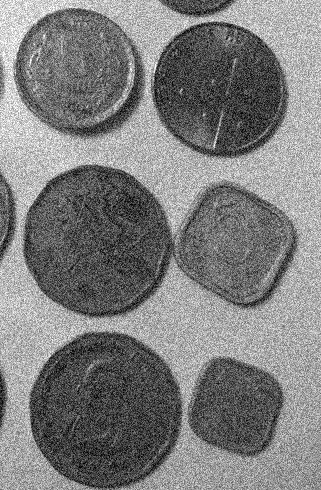

In [8]:
coins_noise = cv2.imread('Monety_szare_szum.bmp', cv2.IMREAD_GRAYSCALE)
Image.fromarray(coins_noise)

Rozwiązanie:

**2.1 Progi Canny'ego bez odszumiania:** od skrajnie niskich do skrajnie wysokich, plus dwie pary pokazujące osobno rolę progu dolnego i górnego.

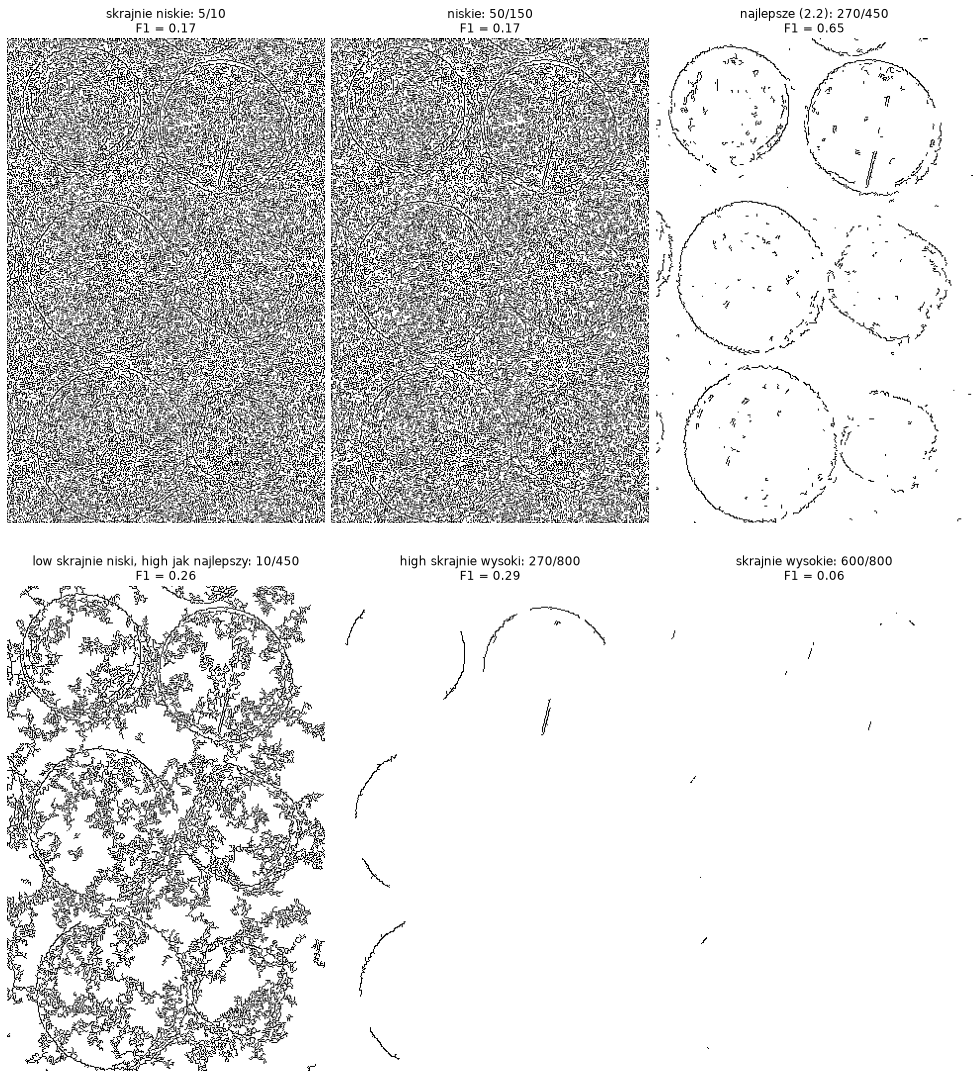

In [9]:
pairs = {'skrajnie niskie': (5, 10), 'niskie': (50, 150), 'najlepsze (2.2)': (270, 450),
         'low skrajnie niski, high jak najlepszy': (10, 450), 'high skrajnie wysoki': (270, 800), 'skrajnie wysokie': (600, 800)}
edges = {name: cv2.Canny(coins_noise, lo, hi) for name, (lo, hi) in pairs.items()}
show_grid(list(edges.values()), [f'{name}: {lo}/{hi}\nF1 = {edge_f1(e):.2f}' for (name, (lo, hi)), e in zip(pairs.items(), edges.values())],
          ncols=3, size=4.5, cmap='gray_r')

**2.2 Mapy F1 po siatce progów** dla trzech wariantów redukcji szumu. Gwiazdka = najlepsza para progów.

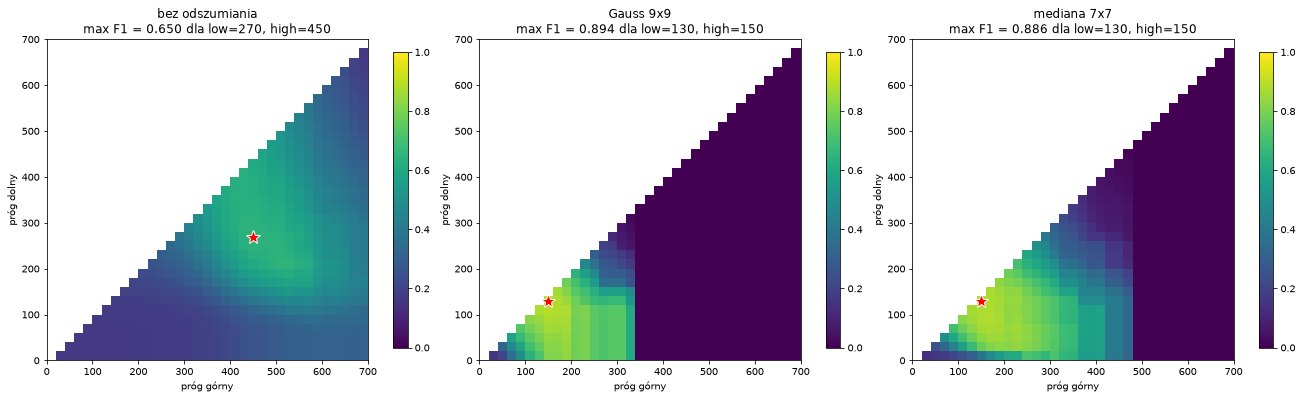

In [10]:
T = np.arange(10, 701, 20)

def canny_scan(src, metric=edge_f1, thresholds=T):
    """Metryka na siatce progów: wiersze = low, kolumny = high; NaN tam, gdzie low >= high."""
    out = np.full((len(thresholds), len(thresholds)), np.nan)
    for i, lo in enumerate(thresholds):
        for j in range(i + 1, len(thresholds)):
            out[i, j] = metric(cv2.Canny(src, lo, thresholds[j]))
    return out

def best(scan, thresholds=T):
    """(najlepsza wartość, low, high)."""
    i, j = np.unravel_index(np.nanargmax(scan), scan.shape)
    return scan[i, j], thresholds[i], thresholds[j]

def scan_ax(ax, scan, title, thresholds=T):
    d = thresholds[1] - thresholds[0]
    im = ax.imshow(scan, origin='lower', extent=(thresholds[0] - d / 2, thresholds[-1] + d / 2) * 2, vmin=0, vmax=1)
    v, lo, hi = best(scan, thresholds)
    ax.plot(hi, lo, 'r*', ms=15, mec='w')
    ax.set_title(f'{title}\nmax F1 = {v:.3f} dla low={lo}, high={hi}'); ax.set_xlabel('próg górny'); ax.set_ylabel('próg dolny')
    plt.colorbar(im, ax=ax, fraction=0.046)

variants = {'bez odszumiania': coins_noise, 'Gauss 9x9': cv2.GaussianBlur(coins_noise, (9, 9), 0), 'mediana 7x7': cv2.medianBlur(coins_noise, 7)}
f1_scans = {name: canny_scan(img) for name, img in variants.items()}
_, axes = plt.subplots(1, 3, figsize=(18, 5.5), constrained_layout=True)
for ax, (name, scan) in zip(axes, f1_scans.items()):
    scan_ax(ax, scan, name)
plt.show()

**2.3 Siła odszumiania:** najlepsze F1 (przy najlepszych progach) w funkcji rozmiaru okna filtra, od 3×3 do skrajnego 61×61. Pod wykresem: obraz i krawędzie dla okna małego, optymalnego i skrajnie dużego.

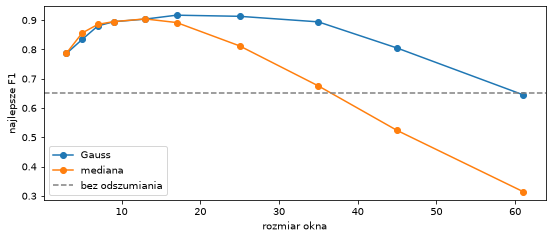

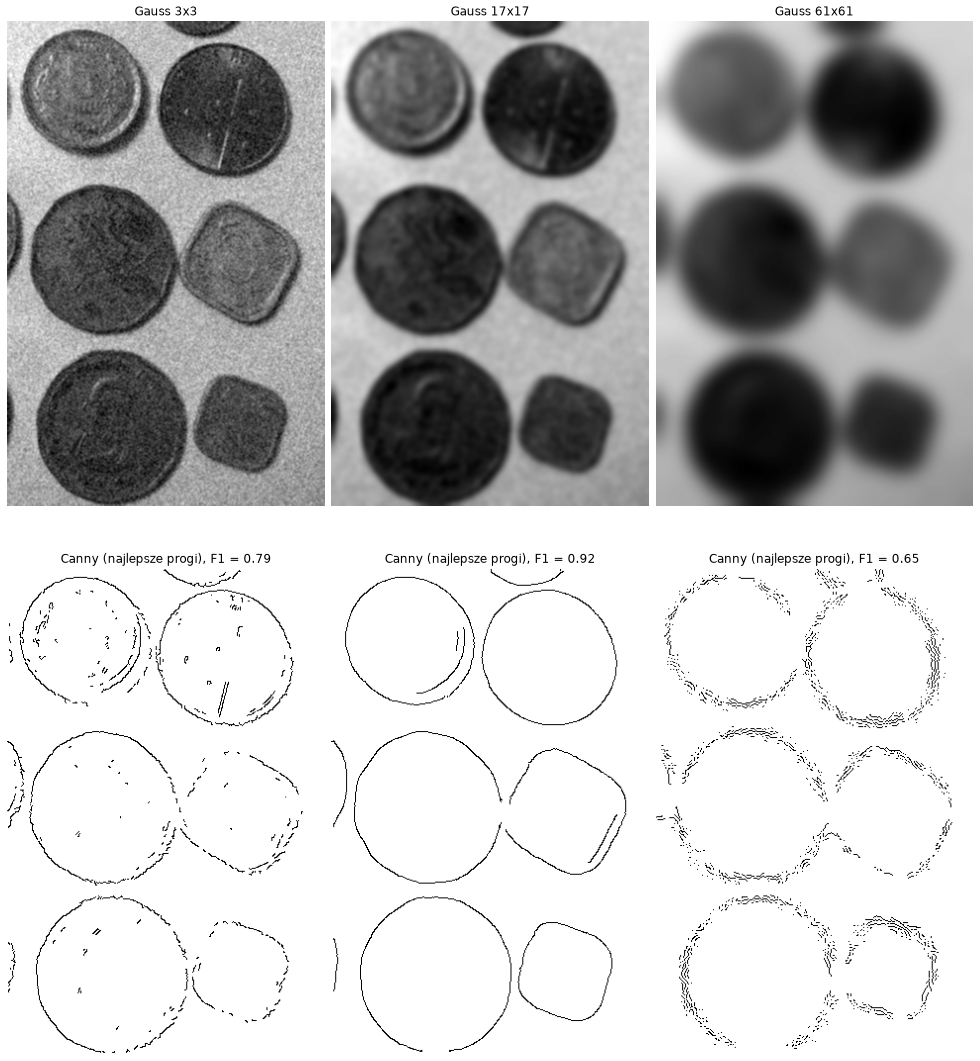

In [11]:
windows = [3, 5, 7, 9, 13, 17, 25, 35, 45, 61]
denoisers = {'Gauss': lambda img, k: cv2.GaussianBlur(img, (k, k), 0), 'mediana': lambda img, k: cv2.medianBlur(img, k)}
plt.figure(figsize=(9, 3.5))
for name, f in denoisers.items():
    plt.plot(windows, [best(canny_scan(f(coins_noise, k)))[0] for k in windows], 'o-', label=name)
plt.axhline(best(f1_scans['bez odszumiania'])[0], color='gray', ls='--', label='bez odszumiania')
plt.xlabel('rozmiar okna'); plt.ylabel('najlepsze F1'); plt.legend(); plt.show()

shown = {}
for k in [3, 17, 61]:
    img = cv2.GaussianBlur(coins_noise, (k, k), 0)
    f1, lo_k, hi_k = best(canny_scan(img))
    shown[k] = (img, cv2.Canny(img, lo_k, hi_k), f1)
show_grid([img for img, _, _ in shown.values()] + [255 - e for _, e, _ in shown.values()],
          [f'Gauss {k}x{k}' for k in shown] + [f'Canny (najlepsze progi), F1 = {f1:.2f}' for _, _, f1 in shown.values()], ncols=3, size=4.5)

**2.4 Wynik końcowy: od krawędzi do obiektów.** Obiekt jest rozpoznany dopiero wtedy, gdy kontur jest *zamknięty*, więc progi dobieram pod IoU obiektów (Gauss 13×13, domknięcie 11), a nie pod F1 krawędzi.

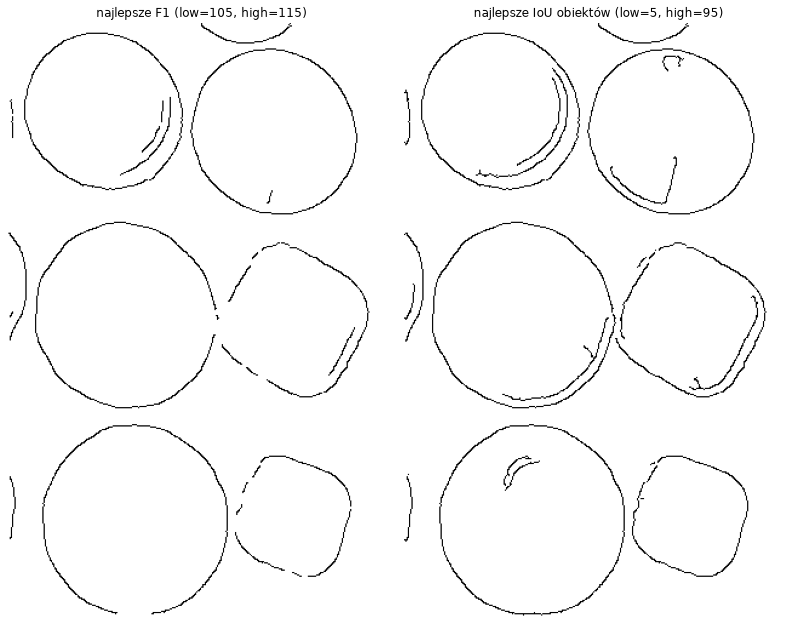

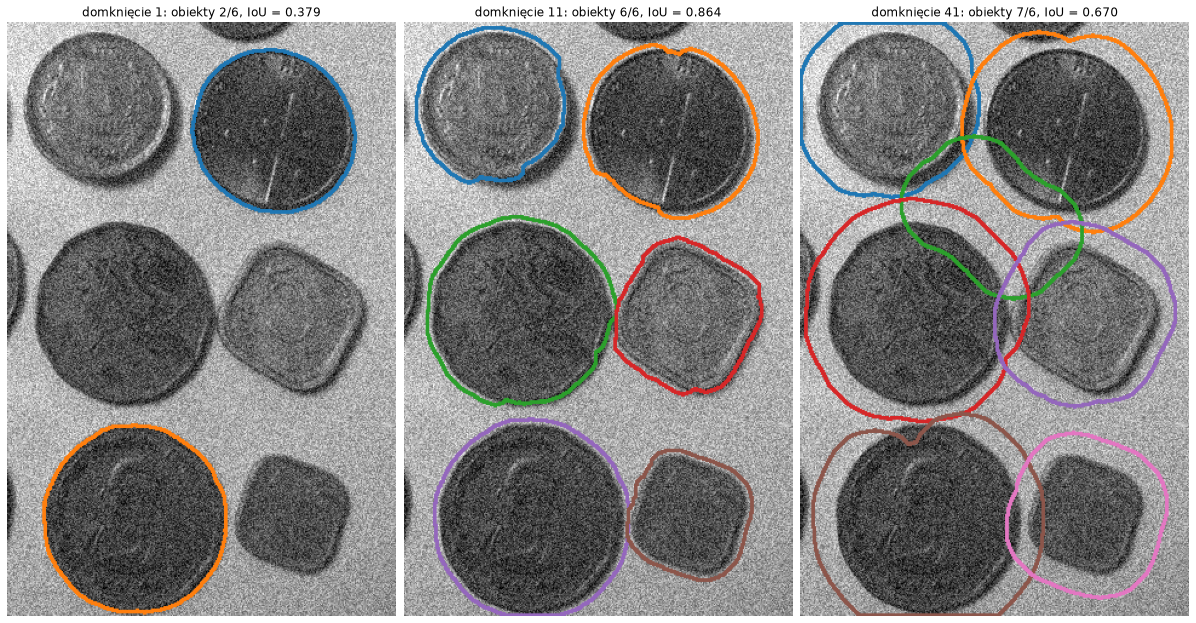

In [12]:
T2 = np.arange(5, 301, 10)
blur13 = cv2.GaussianBlur(coins_noise, (13, 13), 0)
_, lo_f1, hi_f1 = best(canny_scan(blur13, thresholds=T2), T2)
_, lo, hi = best(canny_scan(blur13, lambda e: iou(edges_to_objects(e, 11)[0], gt_mask), T2), T2)

def draw_objects(img, regions):
    """Kontur każdego obiektu osobnym kolorem."""
    rgb = np.dstack([img] * 3)
    for k, region in enumerate(regions):
        contours = cv2.findContours(region, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_NONE)[0]
        cv2.drawContours(rgb, contours, -1, tuple(int(255 * v) for v in plt.cm.tab10(k % 10)[:3]), 2)
    return rgb

edges_final = cv2.Canny(blur13, lo, hi)
show_grid([cv2.Canny(blur13, lo_f1, hi_f1), edges_final], [f'najlepsze F1 (low={lo_f1}, high={hi_f1})', f'najlepsze IoU obiektów (low={lo}, high={hi})'], size=5.5, cmap='gray_r')

images, titles = [], []
for close in [1, 11, 41]:  # bez domknięcia / optymalne / skrajnie duże
    regions = edges_to_regions(edges_final, close)
    images.append(draw_objects(coins_noise, regions))
    titles.append(f'domknięcie {close}: obiekty {len(regions)}/{N_FULL}, IoU = {iou(np.max(regions, axis=0), gt_mask) if regions else 0:.3f}')
show_grid(images, titles, size=5.5)

**Wnioski (zad. 2)**
- **Bez odszumiania** progi stoją przed wyborem między dwiema złymi opcjami. Skrajnie niskie progi dają „spaghetti” z szumu (F1 0.17), skrajnie wysokie zostawiają pojedyncze fragmenty konturów. Sam skrajnie niski `low` przy dobrym `high` też psuje wynik, bo histereza „dociąga” szum podłączony do konturów. Najlepsze F1 to tylko 0.65 (low=270, high=450).
- **Po odszumieniu** optimum przesuwa się do niskich progów (Gauss 9×9: 130/150, F1 = 0.89), a obszar dobrych progów jest szeroki. Silniejsze odszumianie = niższe optymalne progi, bo rozmycie obniża też gradient na konturach.
- **Siła odszumiania:** Gauss i mediana dochodzą do F1 ≈ 0.90 przy oknach 9–17 (Gauss najwyżej: 0.92 przy 17×17). Szum jest gaussowski, a nie typu sól-pieprz, więc mediana nie ma przewagi. Skrajnie duże okno (61×61) rozmywa same monety: Gauss spada do 0.65 (jak bez odszumiania), a mediana do 0.31, bo „zjada” zaokrąglone brzegi i rogi monet.
- **Rozpoznanie obiektów** wymaga zamkniętych konturów, więc najlepiej działa bardzo niski próg dolny (histereza dociąga słabe fragmenty konturu) plus domknięcie. Potok **Gauss 13×13 → Canny(5, 95) → domknięcie 11 → wypełnienie** daje 6/6 pełnych monet przy IoU = 0.86. Bez domknięcia zamykają się tylko 2 monety, a skrajne domknięcie 41 nadmuchuje obiekty i tworzy fałszywy obiekt w luce między monetami (7/6, IoU 0.67).

---

##### Zad. 3: Wyrównanie histogramu

Wyrównaj histogram obrazu `coins_noise`. Wyniki zaprezentuj za pomocą obrazów i towarzyszących im histogramów. Powtórz eksperyment z detekcją krawędzi (zad. 2) dla wyrównanego obrazu i omów różnice.

Rozwiązanie:

max |własne − cv2.equalizeHist| = 0


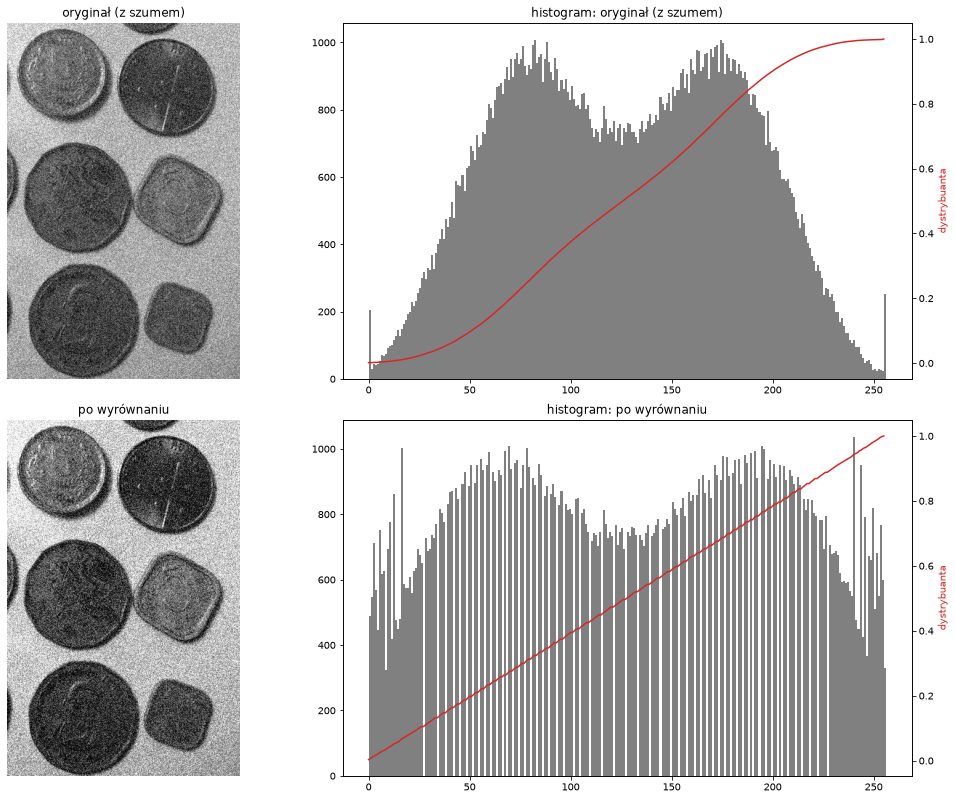

In [13]:
def equalize(img):
    """Wyrównanie histogramu: LUT = dystrybuanta przeskalowana do [0, 255] (jak w cv2.equalizeHist)."""
    hist = np.bincount(img.ravel(), minlength=256)
    cdf = hist.cumsum()
    cdf_min = cdf[hist > 0][0]
    lut = np.round((cdf - cdf_min) / (img.size - cdf_min) * 255).clip(0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

eq = equalize(coins_noise)
print('max |własne − cv2.equalizeHist| =', np.abs(eq.astype(int) - cv2.equalizeHist(coins_noise)).max())

_, axes = plt.subplots(2, 2, figsize=(14, 11), constrained_layout=True, gridspec_kw={'width_ratios': [1, 1.6]})
for row, (name, img) in enumerate([('oryginał (z szumem)', coins_noise), ('po wyrównaniu', eq)]):
    axes[row, 0].imshow(img, cmap='gray', vmin=0, vmax=255); axes[row, 0].set_title(name); axes[row, 0].axis('off')
    axes[row, 1].hist(img.ravel(), 256, range=(0, 256), color='gray'); axes[row, 1].set_title(f'histogram: {name}')
    tw = axes[row, 1].twinx(); tw.plot(np.cumsum(np.bincount(img.ravel(), minlength=256)) / img.size, 'tab:red'); tw.set_ylabel('dystrybuanta', color='tab:red')
plt.show()

**Powtórka detekcji krawędzi z zad. 2 dla obrazu wyrównanego.** Mapy F1 oryginał vs wyrównany, a pod nimi porównanie kolejności operacji (wyrównanie przed / po rozmyciu).

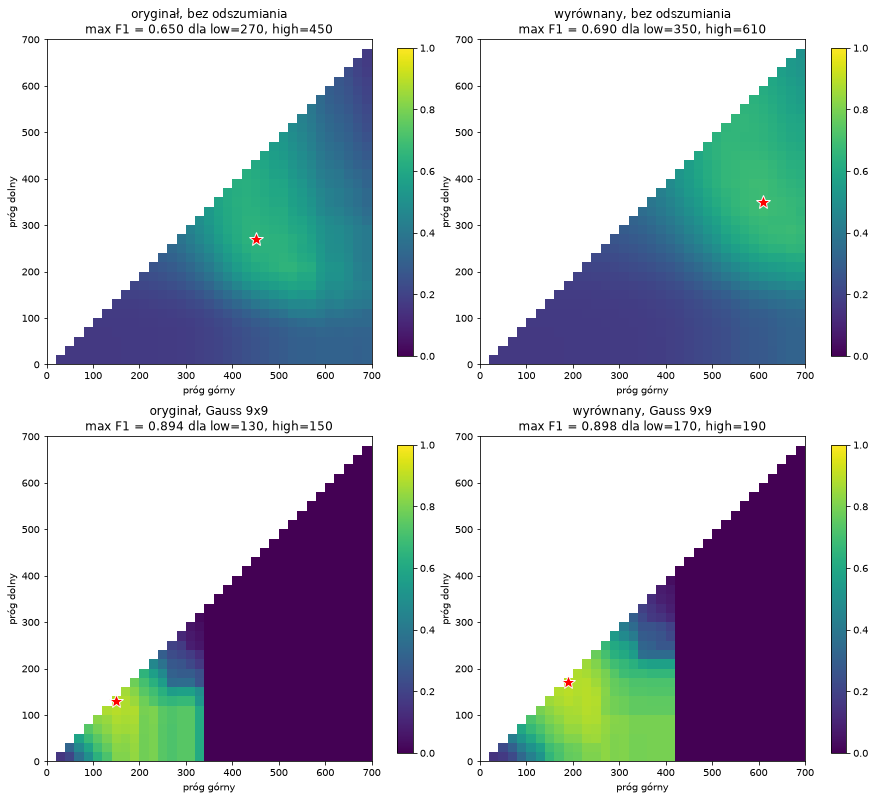

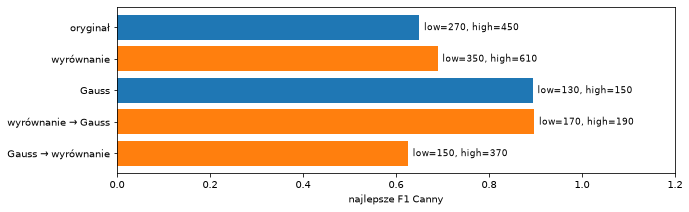

In [14]:
gauss9 = lambda img: cv2.GaussianBlur(img, (9, 9), 0)
_, axes = plt.subplots(2, 2, figsize=(12, 11), constrained_layout=True)
for row, (name, f) in enumerate([('bez odszumiania', lambda img: img), ('Gauss 9x9', gauss9)]):
    scan_ax(axes[row, 0], f1_scans[name], f'oryginał, {name}')
    scan_ax(axes[row, 1], canny_scan(f(eq)), f'wyrównany, {name}')
plt.show()

pipelines = {'oryginał': coins_noise, 'wyrównanie': eq, 'Gauss': gauss9(coins_noise),
             'wyrównanie → Gauss': gauss9(eq), 'Gauss → wyrównanie': equalize(gauss9(coins_noise))}
results = {name: best(canny_scan(img)) for name, img in pipelines.items()}
plt.figure(figsize=(10, 3))
plt.barh(list(results)[::-1], [results[n][0] for n in list(results)[::-1]], color=['C1' if 'wyrównanie' in n else 'C0' for n in list(results)[::-1]])
for k, n in enumerate(list(results)[::-1]):
    plt.text(results[n][0] + 0.01, k, f'low={results[n][1]}, high={results[n][2]}', va='center', fontsize=9)
plt.xlim(0, 1.2); plt.xlabel('najlepsze F1 Canny'); plt.show()

**Wnioski (zad. 3)**
- Histogram obrazu z szumem jest już szeroki, więc wyrównanie zmienia go niewiele. Po wyrównaniu histogram ma „grzebień” (puste koszyki), bo LUT tylko rozsuwa lub skleja istniejące poziomy jasności.
- **Detekcja krawędzi:** wyrównanie praktycznie nie zmienia najlepszego F1 (bez odszumiania 0.65 → 0.69, z Gaussem 0.894 → 0.898), przesuwa tylko optymalne progi w górę, bo rozciąga kontrast. Canny reaguje na różnice jasności względem szumu, a globalna monotoniczna transformacja skaluje jedno i drugie.
- **Kolejność ma znaczenie:** wyrównanie *po* rozmyciu szkodzi (F1 0.89 → 0.63). Po rozmyciu histogram ma dwa wąskie mody; wyrównanie rozciąga mody (wzmacnia resztkowy szum) i ściska dolinę między nimi, w której leżą przejścia na konturach.

---

##### Zad. 4: Transformacja do rozkładu docelowego

Dla obrazów `albatross_single` (od tego zacznij) i `albatross_crowd` wykonaj transformację do wybranego (założonego przez siebie) rozkładu docelowego, tak aby zmaksymalizować możliwość wyodrębnienia obiektów (albatrosów) z otoczenia przy użyciu algorytmu binaryzacji Otsu. Zbadaj wpływ kształtu rozkładu docelowego na zachowanie transformacji.  
Jaki(e) parametr(y) rozkładu są najistotniejsze?

Podpowiedź: przedstawiona we wstępie teoretycznym transformacja obu rozkładów (źródłowego i docelowego) do rozkładu jednostajnego nie musi zostać wykonana _wprost_ (dlatego nie używaj w zadaniu funkcji `cv2.equalizeHist`)! Wystarczy porównywanie ze sobą wartości ze skumulowanych rozkładów (rysunek 3).

Podpowiedź 2: [`cv2.LUT`](https://docs.opencv.org/4.5.3/d2/de8/group__core__array.html#gab55b8d062b7f5587720ede032d34156f)

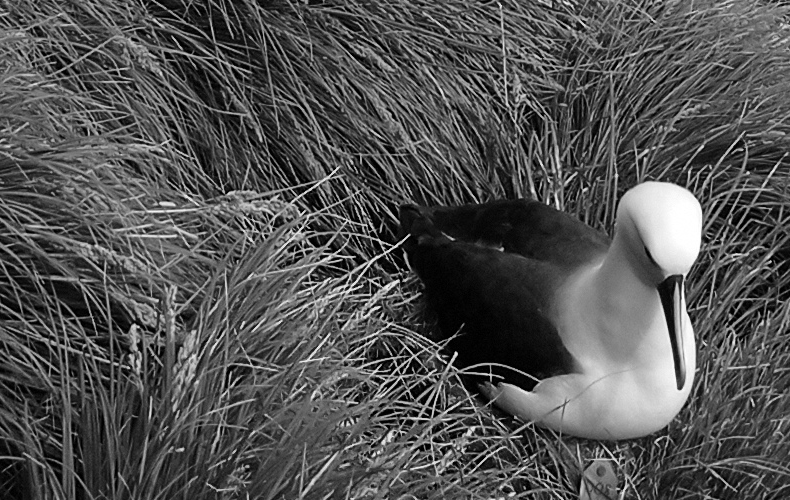

In [15]:
albatross_single = cv2.imread('albatross_single.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_single)

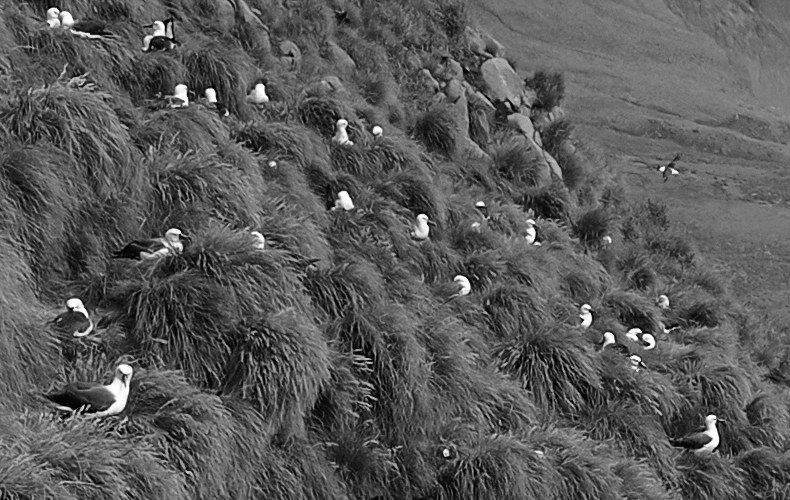

In [16]:
albatross_crowd = cv2.imread('albatross_crowd.png', cv2.IMREAD_GRAYSCALE)
Image.fromarray(albatross_crowd)

Rozwiązanie:

**Implementacja.** Dla każdego poziomu `l` obrazu wybieram najmniejszy poziom celu, którego dystrybuanta jest ≥ dystrybuanty obrazu w `l` (porównanie dystrybuant, bez `cv2.equalizeHist`), i nakładam LUT przez `cv2.LUT`.

Rozkład docelowy to mieszanina dwóch Gaussów: `w` = waga jasnego modu (obiekty), `delta` = odległość modów, `sigma` = szerokość modów, `center` = środek między modami.

In [17]:
from skimage.exposure import match_histograms

L = np.arange(256)

def gauss_pdf(mu, sigma):
    p = np.exp(-0.5 * ((L - mu) / sigma) ** 2)
    return p / p.sum()

def bimodal(w=0.05, center=128, delta=140, sigma=20):
    return (1 - w) * gauss_pdf(center - delta / 2, sigma) + w * gauss_pdf(center + delta / 2, sigma)

def match_histogram(img, target_pdf):
    cdf_src = np.cumsum(np.bincount(img.ravel(), minlength=256)) / img.size
    cdf_tgt = np.cumsum(target_pdf) / np.sum(target_pdf)
    lut = np.searchsorted(cdf_tgt, cdf_src - 1e-9).clip(0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

def otsu_report(img, target_pdf=None, gt=None):
    """Otsu po (opcjonalnej) transformacji; zwraca obraz, maskę, próg, udział pierwszego planu i IoU."""
    out = match_histogram(img, target_pdf) if target_pdf is not None else img
    t, mask = cv2.threshold(out, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return dict(img=out, mask=mask, t=t, fg=(mask > 0).mean(), iou=iou(mask, gt) if gt is not None else None)

# sprawdzenie: obraz referencyjny wylosowany z rozkładu docelowego -> skimage.match_histograms
target = bimodal(w=0.3)
reference = np.random.default_rng(0).choice(256, size=albatross_single.shape, p=target).astype(np.uint8)
diff = np.abs(match_histogram(albatross_single, target).astype(int) - match_histograms(albatross_single, reference).astype(int))
print(f'średnia |własne − skimage| = {diff.mean():.2f} poziomu jasności, max = {diff.max()}')

średnia |własne − skimage| = 0.97 poziomu jasności, max = 2


**Wzorzec** dla `albatross_single`: ręcznie zaznaczony wielokąt jasnej części ptaka. Ciemny grzbiet ma jasność trawy, więc żaden próg globalny go nie wydzieli.

Transformacja histogramu jest monotoniczna, więc maska Otsu po transformacji to i tak `oryginał > t` dla pewnego `t`. Krzywa **IoU(t)** na oryginale wyznacza górną granicę tego, co może dać *jakikolwiek* rozkład docelowy.

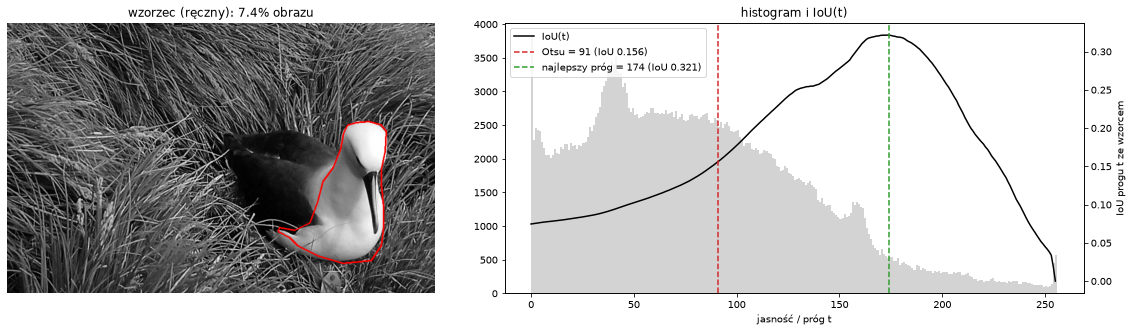

In [18]:
ALB_POLY = np.array([(628, 189), (644, 184), (668, 182), (690, 188), (700, 200), (698, 237), (691, 270), (691, 298), (695, 340), (695, 378), (691, 411), (672, 439), (620, 444),
                     (573, 430), (536, 411), (522, 397), (500, 385), (503, 378), (531, 383), (559, 369), (573, 331), (583, 293), (602, 267), (616, 232), (621, 204)], np.int32)
alb_gt = cv2.fillPoly(np.zeros_like(albatross_single), [ALB_POLY], 255)
GT_FRAC = (alb_gt > 0).mean()
base = otsu_report(albatross_single, gt=alb_gt)
iou_t = np.array([iou(albatross_single > t, alb_gt) for t in L])
T_BEST = int(np.argmax(iou_t))

overlay = np.dstack([albatross_single] * 3)
cv2.polylines(overlay, [ALB_POLY], True, (255, 0, 0), 2)
_, (a1, a2) = plt.subplots(1, 2, figsize=(16, 4.5), constrained_layout=True, gridspec_kw={'width_ratios': [1, 1.2]})
a1.imshow(overlay); a1.set_title(f'wzorzec (ręczny): {100 * GT_FRAC:.1f}% obrazu'); a1.axis('off')
a2.hist(albatross_single.ravel(), 256, range=(0, 256), color='lightgray'); a2.set_xlabel('jasność / próg t')
tw = a2.twinx(); tw.plot(L, iou_t, 'k', label='IoU(t)'); tw.set_ylabel('IoU progu t ze wzorcem')
tw.axvline(base['t'], color='tab:red', ls='--', label=f'Otsu = {base["t"]:.0f} (IoU {base["iou"]:.3f})')
tw.axvline(T_BEST, color='tab:green', ls='--', label=f'najlepszy próg = {T_BEST} (IoU {iou_t[T_BEST]:.3f})')
tw.legend(loc='upper left'); a2.set_title('histogram i IoU(t)'); plt.show()

**4.1 Kształt rozkładu docelowego:** obraz po transformacji, osiągnięty histogram (szary) z rozkładem docelowym (czerwony) i progiem Otsu, maska Otsu.

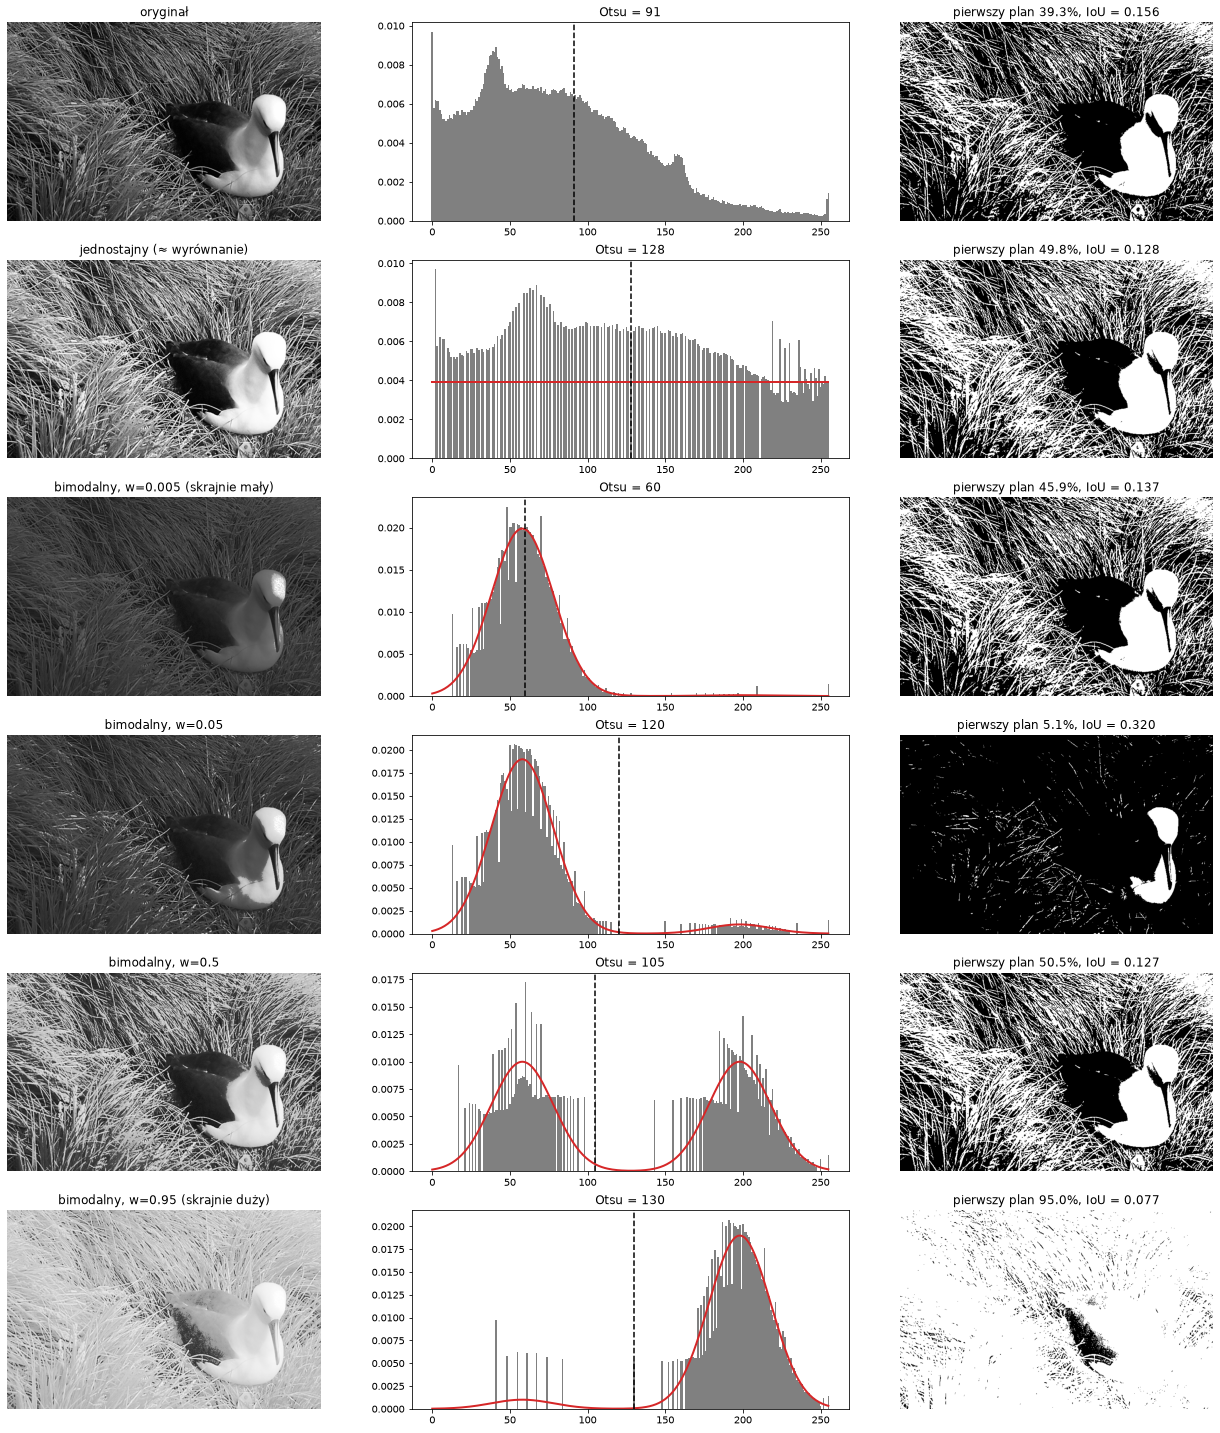

In [19]:
targets = {'jednostajny (≈ wyrównanie)': np.ones(256), 'bimodalny, w=0.005 (skrajnie mały)': bimodal(w=0.005), 'bimodalny, w=0.05': bimodal(w=0.05),
           'bimodalny, w=0.5': bimodal(w=0.5), 'bimodalny, w=0.95 (skrajnie duży)': bimodal(w=0.95)}
rows = {'oryginał': (None, base)} | {name: (pdf, otsu_report(albatross_single, pdf, alb_gt)) for name, pdf in targets.items()}
_, axes = plt.subplots(len(rows), 3, figsize=(18, 3.3 * len(rows)), constrained_layout=True, gridspec_kw={'width_ratios': [1, 1.1, 1]})
for (name, (pdf, r)), (a1, a2, a3) in zip(rows.items(), axes):
    a1.imshow(r['img'], cmap='gray', vmin=0, vmax=255); a1.set_title(name); a1.axis('off')
    a2.bar(L, np.bincount(r['img'].ravel(), minlength=256) / r['img'].size, width=1, color='gray')
    if pdf is not None:
        a2.plot(L, pdf / pdf.sum(), 'tab:red', lw=2)
    a2.axvline(r['t'], color='k', ls='--'); a2.set_title(f'Otsu = {r["t"]:.0f}')
    a3.imshow(r['mask'], cmap='gray'); a3.set_title(f'pierwszy plan {100 * r["fg"]:.1f}%, IoU = {r["iou"]:.3f}'); a3.axis('off')
plt.show()

**4.2 Wpływ każdego parametru osobno**, od wartości skrajnie małych do skrajnie dużych (pozostałe stałe: w=0.05, center=128, delta=140, sigma=20). Pod wykresami maski Otsu dla skrajnych i środkowych wartości `sigma` i `delta`. Szara linia = Otsu na oryginale, zielona = najlepszy możliwy próg globalny.

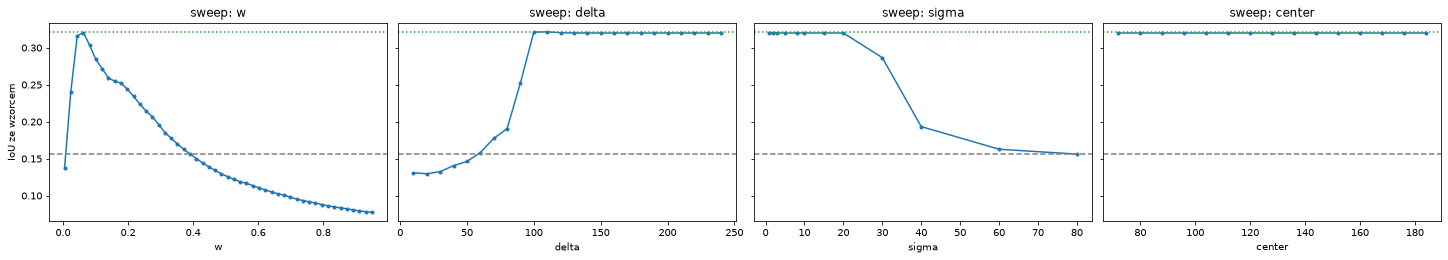

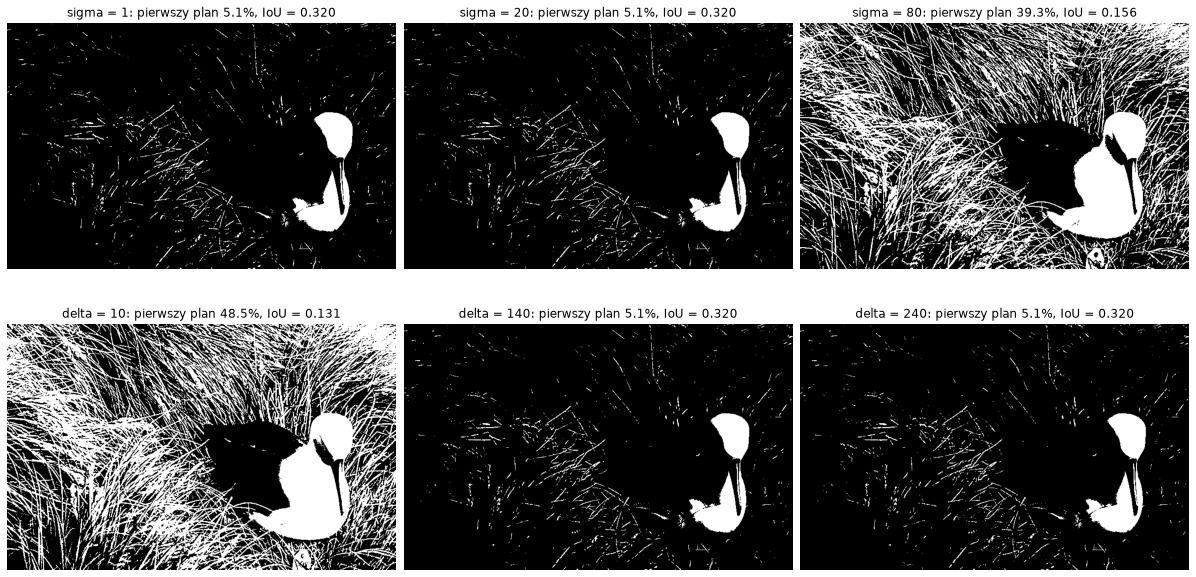

In [20]:
BASE = dict(w=0.05, center=128, delta=140, sigma=20)
sweeps = {
    'w': np.round(np.linspace(0.005, 0.95, 50), 3),
    'delta': np.arange(10, 241, 10),
    'sigma': np.array([1, 2, 3, 5, 8, 10, 15, 20, 30, 40, 60, 80]),
    'center': np.arange(72, 185, 8),
}
_, axes = plt.subplots(1, len(sweeps), figsize=(20, 3.5), sharey=True, constrained_layout=True)
for ax, (p, vals) in zip(axes, sweeps.items()):
    ax.plot(vals, [otsu_report(albatross_single, bimodal(**(BASE | {p: v})), alb_gt)['iou'] for v in vals], 'o-', ms=3)
    ax.axhline(base['iou'], color='gray', ls='--'); ax.axhline(iou_t[T_BEST], color='tab:green', ls=':')
    ax.set_xlabel(p); ax.set_title(f'sweep: {p}')
axes[0].set_ylabel('IoU ze wzorcem'); plt.show()

extremes = [('sigma', 1), ('sigma', 20), ('sigma', 80), ('delta', 10), ('delta', 140), ('delta', 240)]
reports = [otsu_report(albatross_single, bimodal(**(BASE | {p: v})), alb_gt) for p, v in extremes]
show_grid([r['mask'] for r in reports], [f'{p} = {v}: pierwszy plan {100 * r["fg"]:.1f}%, IoU = {r["iou"]:.3f}' for (p, v), r in zip(extremes, reports)], ncols=3, size=5.5)

**4.3 `albatross_crowd`.** Liczba wykrytych obiektów (składowe 20–1500 px) w funkcji `w`; na powiększonym zdjęciu naliczyłem ok. 30 ptaków.

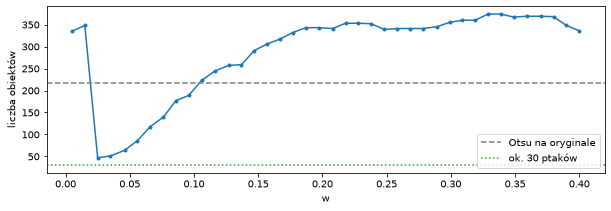

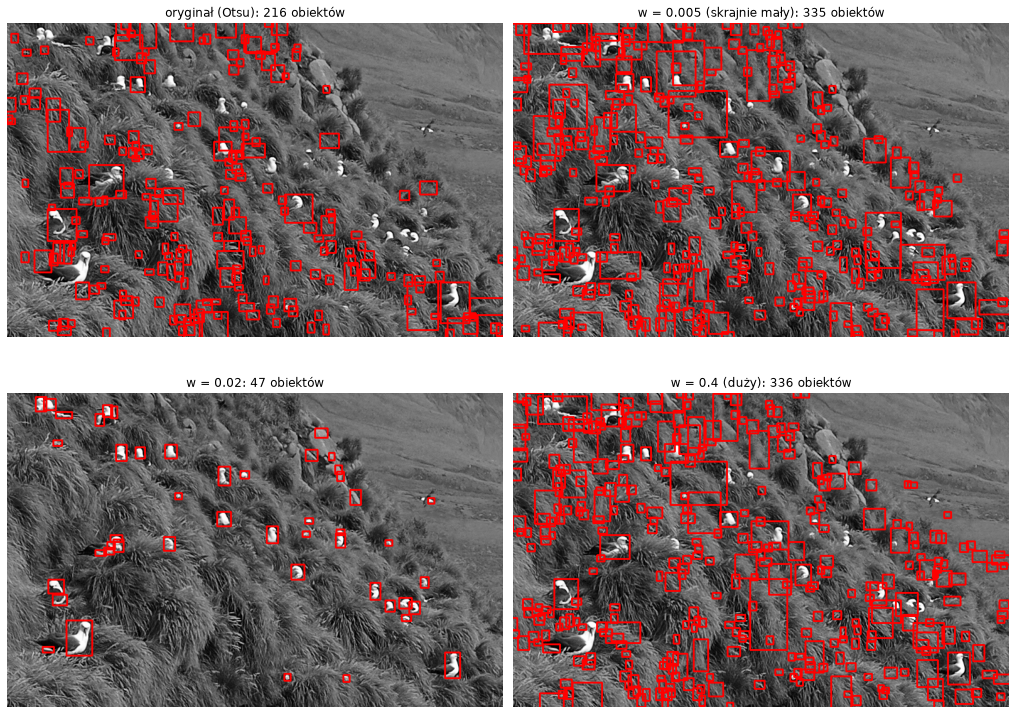

In [21]:
def count_birds(mask, min_area=20, max_area=1500):
    stats = cv2.connectedComponentsWithStats(cv2.morphologyEx(mask, cv2.MORPH_OPEN, ell(3)))[2][1:]
    area = stats[:, cv2.CC_STAT_AREA]
    return stats[(area >= min_area) & (area <= max_area)]

def draw_birds(img, mask):
    rgb = np.dstack([img] * 3)
    for x, y, w, h, _ in count_birds(mask):
        cv2.rectangle(rgb, (x - 2, y - 2), (x + w + 2, y + h + 2), (255, 0, 0), 2)
    return rgb

ws = np.round(np.linspace(0.005, 0.4, 40), 3)
crowd_base = otsu_report(albatross_crowd)
plt.figure(figsize=(10, 3))
plt.plot(ws, [len(count_birds(otsu_report(albatross_crowd, bimodal(**(BASE | {'w': w})))['mask'])) for w in ws], 'o-', ms=3)
plt.axhline(len(count_birds(crowd_base['mask'])), color='gray', ls='--', label='Otsu na oryginale')
plt.axhline(30, color='tab:green', ls=':', label='ok. 30 ptaków')
plt.xlabel('w'); plt.ylabel('liczba obiektów'); plt.legend(); plt.show()

chosen = {'oryginał (Otsu)': crowd_base, 'w = 0.005 (skrajnie mały)': otsu_report(albatross_crowd, bimodal(w=0.005)),
          'w = 0.02': otsu_report(albatross_crowd, bimodal(w=0.02)), 'w = 0.4 (duży)': otsu_report(albatross_crowd, bimodal(w=0.4))}
show_grid([draw_birds(albatross_crowd, r['mask']) for r in chosen.values()], [f'{name}: {len(count_birds(r["mask"]))} obiektów' for name, r in chosen.items()], ncols=2, size=7)

**Wnioski (zad. 4)**
- **Otsu na oryginale** tnie przy 91 i do obiektu trafia 39% obrazu razem z jasną trawą (IoU = 0.16). Najlepszy *możliwy* próg globalny to 174 (IoU = 0.32). To górna granica dla każdej transformacji histogramu, bo jasne źdźbła trawy mają jasność ptaka.
- Rozkład jednostajny i bimodalny z równymi modami (w = 0.5) nie pomagają (IoU ≈ 0.13): Otsu dzieli wtedy obraz mniej więcej na pół.
- Bimodalny rozkład z małą wagą jasnego modu (w = 0.05) osiąga IoU = 0.32, czyli górną granicę. Do obiektu trafia wtedy ≈ w pikseli, bo Otsu tnie w dolinie między modami.
- **Najważniejszy parametr to `w`:** wyznacza, jaka część obrazu zostanie uznana za obiekt. Optimum w ≈ 0.04–0.07 leży blisko faktycznego udziału ptaka (7.4%). Skrajności psują wynik na dwa różne sposoby. Przy w = 0.005 jasny mod jest tak mały, że Otsu go ignoruje i tnie w środku dużego modu (46% obrazu jako obiekt). Przy w = 0.95 obiektem staje się prawie cały obraz (95%), a jako tło zostaje tylko ciemny grzbiet ptaka.
- **Rozdzielenie modów (`delta`, `sigma`)** działa progowo: mody muszą być rozdzielone (delta ≳ 100 przy σ = 20, σ ≲ 25 przy delta = 140), dalsze zmiany niczego nie dają (σ = 1 i σ = 20 dają identyczną maskę). Przy skrajnie zlanych modach (delta = 10 albo σ = 80) wynik wraca do Otsu na oryginale. **`center` nie ma żadnego wpływu.**
- **`albatross_crowd`:** ptaki zajmują mniejszą część obrazu, więc optimum przesuwa się do w ≈ 0.02–0.03: 47 obiektów zamiast 216 dla Otsu na oryginale. Nadwyżka ponad ok. 30 ptaków bierze się z ptaków rozbitych na kilka części i jasnych kamieni. Oba skrajne `w` (0.005 i 0.4) dają ponad 330 obiektów, więcej niż Otsu na oryginale. `w` trzeba więc dobrać do sceny.